In [1]:
# ============================================================
# 02 · Cell 1 — Setup and data load
# ============================================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from commodity_factors.config import PATHS, UNIVERSE, Sector

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

prices = pd.read_parquet(PATHS.processed / "prices_clean.parquet")
curves = pd.read_parquet(PATHS.raw / "eia_curves.parquet")

print(f"Front-month prices : {prices.shape[0]:,} days x {prices.shape[1]} contracts | "
      f"{prices.index.min():%Y-%m-%d} -> {prices.index.max():%Y-%m-%d}")
print(f"EIA curves         : {curves.shape[0]:,} days x {curves.shape[1]} series | "
      f"{curves.index.min():%Y-%m-%d} -> {curves.index.max():%Y-%m-%d}")

Front-month prices : 6,754 days x 26 contracts | 2000-01-03 -> 2026-10-16
EIA curves         : 11,127 days x 15 series | 1980-01-02 -> 2024-04-05


In [2]:
# ============================================================
# 02 · Cell 2 — Diagnose Yahoo's roll convention against EIA
# ============================================================
ENERGY = ["CL", "HO", "NG", "RB"]
TOLERANCE = 0.0025  # prices within 0.25% count as the same contract


def match_contract(yahoo: pd.Series, curve: pd.DataFrame, tolerance: float) -> pd.Series:
    """For each day, the EIA contract number closest to the Yahoo price (0 = no match)."""
    common = yahoo.dropna().index.intersection(curve.dropna(how="all").index)
    gaps = (
        curve.loc[common]
        .sub(yahoo.loc[common], axis=0)
        .abs()
        .div(yahoo.loc[common].abs(), axis=0)
    )
    nearest = gaps.idxmin(axis=1)
    return nearest.where(gaps.min(axis=1) <= tolerance, 0).astype(int).rename("matched_contract")


matches = {
    symbol: match_contract(prices[symbol].loc[:"2024-04-05"], curves[symbol], TOLERANCE)
    for symbol in ENERGY
}

match_share = (
    pd.DataFrame({s: m.value_counts(normalize=True).mul(100) for s, m in matches.items()})
    .fillna(0)
    .round(1)
    .rename(index=lambda c: "no match" if c == 0 else f"contract {c}")
    .sort_index()
)
print("Share of days Yahoo matches each EIA contract (%)")
print(match_share.to_string(), "\n")

contract2_days = pd.DataFrame(
    {s: m[m == 2].index.day.value_counts() for s, m in matches.items()}
).fillna(0).astype(int).sort_index()
print("Days Yahoo matched contract 2, by day of month")
print(contract2_days.T.to_string())

Share of days Yahoo matches each EIA contract (%)
                    CL    HO    NG    RB
matched_contract                        
contract 1        98.9  98.7  97.9  98.9
contract 2         0.1   0.5   0.3   0.0
contract 3         0.1   0.1   0.0   0.0
contract 4         0.1   0.0   0.0   0.0
no match           0.9   0.7   1.8   1.0 

Days Yahoo matched contract 2, by day of month
date  1   2   3   4   5   6   7   8   10  11  12  15  16  18  20  21  22  23  25  26  27  28  30  31
CL     0   0   0   0   0   1   0   0   0   0   0   0   0   0   1   1   0   0   0   0   0   0   0   1
HO     1   0   1   1   1   2   1   2   1   1   2   1   1   1   0   1   1   0   4   2   1   1   1   2
NG     7   1   1   0   0   0   0   1   0   0   0   1   1   0   3   1   0   1   1   0   1   0   0   0
RB     0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1   0   0   0   0   0   0   0   0


In [7]:
%%writefile src/commodity_factors/contracts.py
"""Contract listing months, last-trading-day rules and roll calendars."""

from __future__ import annotations

from abc import ABC, abstractmethod
from dataclasses import dataclass

import pandas as pd

MONTH_CODES: dict[str, int] = dict(zip("FGHJKMNQUVXZ", range(1, 13)))
ALL_MONTHS = "FGHJKMNQUVXZ"


class TradingCalendar:
    """Business-day arithmetic on an observed set of trading days."""

    def __init__(self, trading_days: pd.DatetimeIndex) -> None:
        self._days = pd.DatetimeIndex(trading_days).unique().sort_values()
        self._months = self._days.to_period("M")

    def month_days(self, year: int, month: int, offset: int = 0) -> pd.DatetimeIndex:
        period = pd.Period(year=year, month=month, freq="M") + offset
        return self._days[self._months == period]

    def shift(self, date: pd.Timestamp, n: int) -> pd.Timestamp | None:
        position = self._days.get_loc(date) + n
        return self._days[position] if 0 <= position < len(self._days) else None


class ExpiryRule(ABC):
    """Maps a delivery month to its last trading day on a given calendar."""

    @abstractmethod
    def last_trading_day(self, year: int, month: int, calendar: TradingCalendar):
        """Return the last trading day as a Timestamp, or None if outside the calendar."""


@dataclass(frozen=True)
class BusinessDaysBeforeMonthEnd(ExpiryRule):
    """k-th business day before the last business day of (delivery month + offset)."""

    month_offset: int = 0
    days_before: int = 0

    def last_trading_day(self, year, month, calendar):
        days = calendar.month_days(year, month, self.month_offset)
        return days[-1 - self.days_before] if len(days) > self.days_before else None


@dataclass(frozen=True)
class BusinessDaysBeforeCalendarDay(ExpiryRule):
    """k business days before the last business day on or before calendar day ``day``."""

    day: int
    month_offset: int = 0
    days_before: int = 0

    def last_trading_day(self, year, month, calendar):
        days = calendar.month_days(year, month, self.month_offset)
        eligible = days[days.day <= self.day]
        return calendar.shift(eligible[-1], -self.days_before) if len(eligible) else None


@dataclass(frozen=True)
class NthBusinessDayOfMonth(ExpiryRule):
    """n-th business day of the delivery month (1-based)."""

    n: int

    def last_trading_day(self, year, month, calendar):
        days = calendar.month_days(year, month)
        return days[self.n - 1] if len(days) >= self.n else None


@dataclass(frozen=True)
class LastWeekdayOfMonth(ExpiryRule):
    """Last trading day of the delivery month falling on ``weekday`` (Mon=0)."""

    weekday: int

    def last_trading_day(self, year, month, calendar):
        days = calendar.month_days(year, month)
        matches = days[days.weekday == self.weekday]
        return matches[-1] if len(matches) else None


@dataclass(frozen=True)
class ContractSpec:
    """Delivery months (exchange month codes) and the last-trading-day rule."""

    symbol: str
    month_codes: str
    rule: ExpiryRule

    @property
    def delivery_months(self) -> tuple[int, ...]:
        return tuple(MONTH_CODES[code] for code in self.month_codes)

    def last_trading_days(self, calendar: TradingCalendar, years: range) -> pd.Series:
        expiries = {}
        for year in years:
            for month in self.delivery_months:
                period = pd.Period(year=year, month=month, freq="M")
                expiries[period] = self.rule.last_trading_day(year, month, calendar)
        return pd.Series(expiries, name="last_trading_day").dropna().sort_values()


_METALS = BusinessDaysBeforeMonthEnd(days_before=2)   # third-last business day
_GRAINS = BusinessDaysBeforeCalendarDay(day=14)       # business day prior to the 15th

_SPECS = (
    ContractSpec("CL", ALL_MONTHS, BusinessDaysBeforeCalendarDay(25, -1, 3)),
    ContractSpec("BZ", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-2, 0)),
    ContractSpec("NG", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-1, 2)),
    ContractSpec("HO", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-1, 0)),
    ContractSpec("RB", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-1, 0)),
    ContractSpec("GC", "GJMQVZ", _METALS),
    ContractSpec("SI", "HKNUZ", _METALS),
    ContractSpec("HG", "HKNUZ", _METALS),
    ContractSpec("PL", "FJNV", _METALS),
    ContractSpec("PA", "HMUZ", _METALS),
    ContractSpec("ZC", "HKNUZ", _GRAINS),
    ContractSpec("ZW", "HKNUZ", _GRAINS),
    ContractSpec("KE", "HKNUZ", _GRAINS),
    ContractSpec("ZS", "FHKNQUX", _GRAINS),
    ContractSpec("ZM", "FHKNQUVZ", _GRAINS),
    ContractSpec("ZL", "FHKNQUVZ", _GRAINS),
    ContractSpec("ZO", "HKNUZ", _GRAINS),
    ContractSpec("ZR", "FHKNUX", _GRAINS),
    ContractSpec("KC", "HKNUZ", BusinessDaysBeforeMonthEnd(0, 8)),
    ContractSpec("SB", "HKNV", BusinessDaysBeforeMonthEnd(-1, 0)),
    ContractSpec("CC", "HKNUZ", BusinessDaysBeforeMonthEnd(0, 11)),
    ContractSpec("CT", "HKNVZ", BusinessDaysBeforeMonthEnd(0, 16)),
    ContractSpec("OJ", "FHKNUX", BusinessDaysBeforeMonthEnd(0, 14)),
    ContractSpec("LE", "GJMQVZ", BusinessDaysBeforeMonthEnd(0, 0)),
    ContractSpec("HE", "GJKMNQVZ", NthBusinessDayOfMonth(10)),
    ContractSpec("GF", "FHJKQUVX", LastWeekdayOfMonth(3)),
)
CONTRACT_SPECS: dict[str, ContractSpec] = {spec.symbol: spec for spec in _SPECS}


class RollCalendar:
    """Roll dates for stitched front-month series that switch contract after expiry.

    The roll date is the first day the series has a price after the expiring
    contract's last trading day: the day its return spans two contracts.
    """

    def __init__(self, specs: dict[str, ContractSpec], calendar: TradingCalendar) -> None:
        self._specs = specs
        self._calendar = calendar

    def last_trading_days(self, symbol: str, years: range) -> pd.Series:
        return self._specs[symbol].last_trading_days(self._calendar, years)

    def roll_dates(self, symbol: str, series_dates: pd.DatetimeIndex) -> pd.DatetimeIndex:
        series_dates = pd.DatetimeIndex(series_dates).sort_values()
        years = range(series_dates[0].year, series_dates[-1].year + 2)
        expiries = pd.DatetimeIndex(self.last_trading_days(symbol, years).to_numpy())
        positions = series_dates.searchsorted(expiries, side="right")
        rolls = series_dates[positions[positions < len(series_dates)]]
        return pd.DatetimeIndex(rolls[rolls > series_dates[0]].unique(), name="roll_date")

Overwriting src/commodity_factors/contracts.py


In [8]:
# ============================================================
# 02 · Cell 4 — Build roll calendar and test it against the data
# ============================================================
from commodity_factors.contracts import CONTRACT_SPECS, RollCalendar, TradingCalendar

OFFSETS = range(-3, 4)
LARGE_MOVE = 0.20

roll_calendar = RollCalendar(CONTRACT_SPECS, TradingCalendar(prices.index))

roll_dates: dict[str, pd.DatetimeIndex] = {}
diagnostics: dict[str, dict] = {}

for symbol in UNIVERSE.symbols:
    series = prices[symbol].dropna()
    abs_log_ret = np.log(series.where(series > 0)).diff().abs()
    simple_ret = series.pct_change()

    rolls = roll_calendar.roll_dates(symbol, series.index)
    roll_dates[symbol] = rolls
    positions = series.index.get_indexer(rolls)
    baseline = abs_log_ret.median()

    profile = {}
    for k in OFFSETS:
        shifted = positions + k
        shifted = shifted[(shifted >= 1) & (shifted < len(series))]
        profile[f"{k:+d}"] = abs_log_ret.iloc[shifted].median() / baseline

    large = simple_ret.abs() > LARGE_MOVE
    years = (series.index[-1] - series.index[0]).days / 365.25
    diagnostics[symbol] = {
        "listed": len(CONTRACT_SPECS[symbol].month_codes),
        "rolls_per_yr": len(rolls) / years,
        **profile,
        "large_moves": int(large.sum()),
        "large_on_roll": int(large.loc[large.index.isin(rolls)].sum()),
    }

roll_test = pd.DataFrame(diagnostics).T
roll_test = roll_test.astype({"listed": int, "large_moves": int, "large_on_roll": int}).round(2)
roll_test.insert(0, "sector", UNIVERSE.to_frame()["sector"])

print("Roll-day profile: median |return| around roll dates / normal median |return|")
print("(offset 0 should stand out; neighbours should sit near 1)\n")
print(roll_test.to_string())

Roll-day profile: median |return| around roll dates / normal median |return|
(offset 0 should stand out; neighbours should sit near 1)

       sector  listed  rolls_per_yr    -3    -2    -1    +0    +1    +2    +3  large_moves  large_on_roll
CL     Energy      12         12.01  0.99  0.95  0.95  1.23  1.00  0.87  0.87           11              1
BZ     Energy      12         12.02  1.08  0.88  0.84  1.40  1.38  1.01  1.04            3              0
NG     Energy      12         12.02  1.09  0.82  1.28  1.67  0.92  1.12  1.02           15              9
HO     Energy      12         11.98  1.01  0.98  1.05  1.45  1.11  1.05  0.98            1              0
RB     Energy      12         11.98  1.11  1.07  0.99  1.74  1.19  0.93  0.97           10              3
GC     Metals       6          6.01  0.87  1.00  0.90  1.00  1.04  1.17  1.26            0              0
SI     Metals       5          5.01  0.86  1.02  0.99  1.03  1.17  1.08  1.12            1              0
HG     Metals   

In [9]:
import py_compile

path = PATHS.root / "src" / "commodity_factors" / "contracts.py"
lines = path.read_text(encoding="utf-8").splitlines()
print(f"{len(lines)} lines in file (expected ~205)\n")
for number in range(100, min(125, len(lines))):
    print(f"{number + 1:4d} | {lines[number]}")

py_compile.compile(str(path), doraise=True)
print("\nFile compiles OK")

162 lines in file (expected ~205)

 101 |         for year in years:
 102 |             for month in self.delivery_months:
 103 |                 period = pd.Period(year=year, month=month, freq="M")
 104 |                 expiries[period] = self.rule.last_trading_day(year, month, calendar)
 105 |         return pd.Series(expiries, name="last_trading_day").dropna().sort_values()
 106 | 
 107 | 
 108 | _METALS = BusinessDaysBeforeMonthEnd(days_before=2)   # third-last business day
 109 | _GRAINS = BusinessDaysBeforeCalendarDay(day=14)       # business day prior to the 15th
 110 | 
 111 | _SPECS = (
 112 |     ContractSpec("CL", ALL_MONTHS, BusinessDaysBeforeCalendarDay(25, -1, 3)),
 113 |     ContractSpec("BZ", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-2, 0)),
 114 |     ContractSpec("NG", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-1, 2)),
 115 |     ContractSpec("HO", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-1, 0)),
 116 |     ContractSpec("RB", ALL_MONTHS, BusinessDaysBeforeMonthEnd(-1, 0)),

In [10]:
# ============================================================
# 02 · Cell 5 — Locate Yahoo's roll day for metals (signed-return scan)
# ============================================================
METALS = UNIVERSE.by_sector(Sector.METALS).symbols
SCAN = range(-10, 23)


def roll_scan_tstats(symbol: str, offsets: range) -> pd.Series:
    """t-stat of mean signed log return at each offset from the delivery month's first trading day."""
    series = prices[symbol].dropna()
    log_ret = np.log(series.where(series > 0)).diff()
    calendar = TradingCalendar(series.index)
    spec = CONTRACT_SPECS[symbol]

    anchors = []
    for year in range(series.index[0].year, series.index[-1].year + 1):
        for month in spec.delivery_months:
            days = calendar.month_days(year, month)
            if len(days):
                anchors.append(days[0])
    positions = series.index.get_indexer(pd.DatetimeIndex(anchors))

    daily_std = log_ret.std()
    stats = {}
    for k in offsets:
        idx = positions + k
        sample = log_ret.iloc[idx[(idx >= 1) & (idx < len(series))]].dropna()
        stats[k] = sample.mean() / (daily_std / np.sqrt(len(sample)))
    return pd.Series(stats, name=symbol)


scan = pd.DataFrame({symbol: roll_scan_tstats(symbol, SCAN) for symbol in METALS}).round(1)
scan.index.name = "offset"

print("t-stat of mean signed return, by business day relative to delivery month start")
print("(offset 0 = first trading day of delivery month; |t| > 3 marks a likely roll day)\n")
print(scan.to_string(), "\n")

print("Top 3 offsets by |t| per metal")
for symbol in METALS:
    top = scan[symbol].abs().nlargest(3)
    print(f"  {symbol}: " + ", ".join(f"{k:+d} (t={scan.at[k, symbol]})" for k in top.index))

t-stat of mean signed return, by business day relative to delivery month start
(offset 0 = first trading day of delivery month; |t| > 3 marks a likely roll day)

         GC   SI   HG   PL   PA
offset                         
-10     1.1  1.0  0.9 -0.9 -0.1
-9      2.8  0.6 -0.3 -1.3  0.3
-8     -0.1 -0.1 -0.0  0.8  0.7
-7      0.3 -0.9  1.0 -1.7 -1.1
-6      0.2 -0.4  0.6  0.1 -0.8
-5      1.2  0.7  0.6 -0.3 -1.2
-4     -1.0 -0.0  1.3  1.0 -0.3
-3     -0.6  0.0 -0.2 -1.2  1.1
-2      0.5 -1.2 -0.8 -1.0  0.7
-1      1.6  1.2  1.7  1.6  0.3
0       3.4  0.9  1.4  0.9  1.4
1      -0.3  0.4  0.3  2.3 -0.1
2      -0.4  0.8  0.8 -0.4 -0.0
3       1.3 -0.4 -0.3  0.0  1.8
4      -0.5  0.1 -0.5  0.1 -0.3
5       1.2 -0.4  0.7  0.3 -0.0
6       0.5  0.9 -0.4  2.3  0.2
7       0.8  0.7  0.5  1.3 -0.5
8      -0.1  0.3  1.1  1.4 -1.2
9       0.7 -1.6 -1.6  0.2 -1.3
10     -1.7 -2.0 -0.7 -0.3  0.0
11      1.9  0.3  0.4  1.0  0.0
12      0.0  1.2 -0.7 -1.1 -1.4
13      1.5 -0.3  1.0  1.6 -0.4
14    

In [11]:
# ============================================================
# 02 · Cell 6 — Apply metals roll fix and roll-mask settings
# ============================================================
import importlib

import commodity_factors.config as config_module
import commodity_factors.contracts as contracts_module

CONTRACTS_PATH = PATHS.root / "src" / "commodity_factors" / "contracts.py"
CONFIG_PATH = PATHS.root / "src" / "commodity_factors" / "config.py"

OLD_METALS = "_METALS = BusinessDaysBeforeMonthEnd(days_before=2)   # third-last business day"
NEW_METALS = (
    "_METALS = BusinessDaysBeforeMonthEnd(month_offset=-1, days_before=1)"
    "  # Yahoo rolls at the month boundary before delivery"
)

ROLL_MASK_BLOCK = '''

# ------------------------------------------------------------------ roll masking
# Consecutive days masked from each roll date (default 1 = roll day only).
# Metals: Yahoo switches on day -1 or 0 around the delivery-month boundary.
# Brent: Yahoo sometimes switches one day after the computed roll date.
ROLL_MASK_DAYS: dict[str, int] = {"BZ": 2, "GC": 2, "SI": 2, "HG": 2, "PL": 2, "PA": 2}
'''

# 1. Metals rule -> month boundary before delivery
contracts_source = CONTRACTS_PATH.read_text(encoding="utf-8")
if OLD_METALS in contracts_source:
    CONTRACTS_PATH.write_text(contracts_source.replace(OLD_METALS, NEW_METALS), encoding="utf-8")
    print("contracts.py : metals rule updated")
elif NEW_METALS in contracts_source:
    print("contracts.py : metals rule already updated")
else:
    raise ValueError("Metals rule line not found in contracts.py; check the file.")

# 2. Roll-mask settings -> config
config_source = CONFIG_PATH.read_text(encoding="utf-8")
if "ROLL_MASK_DAYS" not in config_source:
    CONFIG_PATH.write_text(config_source.rstrip() + "\n" + ROLL_MASK_BLOCK, encoding="utf-8")
    print("config.py    : ROLL_MASK_DAYS added")
else:
    print("config.py    : ROLL_MASK_DAYS already present")

# 3. Reload modules and rebuild the roll calendar
importlib.reload(config_module)
importlib.reload(contracts_module)
from commodity_factors.config import ROLL_MASK_DAYS
from commodity_factors.contracts import CONTRACT_SPECS, RollCalendar, TradingCalendar

roll_calendar = RollCalendar(CONTRACT_SPECS, TradingCalendar(prices.index))
roll_dates = {
    symbol: roll_calendar.roll_dates(symbol, prices[symbol].dropna().index)
    for symbol in UNIVERSE.symbols
}

# 4. Verify
years = {s: (prices[s].dropna().index[-1] - prices[s].dropna().index[0]).days / 365.25
         for s in UNIVERSE.symbols}
check = pd.DataFrame(
    {
        "sector": UNIVERSE.to_frame()["sector"],
        "listed": {s: len(CONTRACT_SPECS[s].month_codes) for s in UNIVERSE.symbols},
        "rolls_per_yr": {s: round(len(roll_dates[s]) / years[s], 2) for s in UNIVERSE.symbols},
        "mask_days": {s: ROLL_MASK_DAYS.get(s, 1) for s in UNIVERSE.symbols},
    }
)
print("\nRoll calendar check")
print(check.to_string(), "\n")

print("Last 4 metal roll dates (should be the last trading day before each delivery month)")
for symbol in UNIVERSE.by_sector(Sector.METALS).symbols:
    print(f"  {symbol}: {[d.strftime('%Y-%m-%d') for d in roll_dates[symbol][-4:]]}")

contracts.py : metals rule updated
config.py    : ROLL_MASK_DAYS added

Roll calendar check
       sector  listed  rolls_per_yr  mask_days
CL     Energy      12         12.01          1
BZ     Energy      12         12.02          2
NG     Energy      12         12.02          1
HO     Energy      12         11.98          1
RB     Energy      12         11.98          1
GC     Metals       6          6.01          2
SI     Metals       5          5.01          2
HG     Metals       5          5.01          2
PL     Metals       4          3.99          2
PA     Metals       4          3.99          2
ZC     Grains       5          4.99          1
ZW     Grains       5          4.99          1
KE     Grains       5          4.99          1
ZS     Grains       7          6.98          1
ZM     Grains       8          8.02          1
ZL     Grains       8          8.01          1
ZO     Grains       5          5.00          1
ZR     Grains       6          6.01          1
KC      Softs  

In [12]:
%%writefile src/commodity_factors/returns.py
"""Roll-adjusted excess returns from stitched front-month futures prices."""

from __future__ import annotations

from collections.abc import Iterable, Mapping
from dataclasses import dataclass

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class ReturnOverride:
    """Replacement daily returns for one contract over a date window."""

    symbol: str
    start: str
    end: str
    returns: pd.Series
    reason: str


@dataclass(frozen=True)
class ReturnSet:
    """Clean daily and monthly excess returns, a return index and the roll mask used."""

    daily: pd.DataFrame
    monthly: pd.DataFrame
    index: pd.DataFrame
    roll_mask: pd.DataFrame


class ExcessReturnBuilder:
    """Builds roll-adjusted excess returns from a wide panel of front-month prices.

    Returns are computed on each contract's own trading days, then the return on
    each roll date (and ``mask_days - 1`` following days) is removed, because it
    spans two different contracts. Futures returns are excess returns by
    construction: no collateral yield is added.
    """

    def __init__(
        self,
        roll_dates: Mapping[str, pd.DatetimeIndex],
        mask_days: Mapping[str, int] | None = None,
        min_days_per_month: int = 10,
    ) -> None:
        self._roll_dates = roll_dates
        self._mask_days = mask_days or {}
        self._min_days_per_month = min_days_per_month

    def build(self, prices: pd.DataFrame, overrides: Iterable[ReturnOverride] = ()) -> ReturnSet:
        raw = pd.DataFrame({s: prices[s].dropna().pct_change() for s in prices}).reindex(prices.index)
        roll_mask = self._roll_mask(prices)
        daily = raw.mask(roll_mask)
        for override in overrides:
            daily = self._apply_override(daily, override)

        started = prices.notna().cummax()
        index = (1 + daily.fillna(0)).cumprod().mul(100).where(started)
        return ReturnSet(
            daily=daily,
            monthly=self._to_monthly(daily),
            index=index,
            roll_mask=roll_mask,
        )

    def _roll_mask(self, prices: pd.DataFrame) -> pd.DataFrame:
        mask = pd.DataFrame(False, index=prices.index, columns=prices.columns)
        for symbol in prices:
            own_dates = prices[symbol].dropna().index
            positions = own_dates.get_indexer(self._roll_dates.get(symbol, pd.DatetimeIndex([])))
            positions = positions[positions >= 0]
            span = self._mask_days.get(symbol, 1)
            masked = np.unique(np.concatenate([positions + k for k in range(span)]))
            mask.loc[own_dates[masked[masked < len(own_dates)]], symbol] = True
        return mask

    @staticmethod
    def _apply_override(daily: pd.DataFrame, override: ReturnOverride) -> pd.DataFrame:
        window = daily.loc[override.start : override.end].index
        daily = daily.copy()
        daily.loc[window, override.symbol] = override.returns.reindex(window)
        return daily

    def _to_monthly(self, daily: pd.DataFrame) -> pd.DataFrame:
        log_sum = np.log1p(daily).resample("ME").sum(min_count=1)
        counts = daily.resample("ME").count()
        return np.expm1(log_sum).where(counts >= self._min_days_per_month)

Writing src/commodity_factors/returns.py


In [13]:
# ============================================================
# 02 · Cell 8 — Build clean excess returns and compare with raw
# ============================================================
from commodity_factors.returns import ExcessReturnBuilder, ReturnOverride

TRADING_DAYS = 252

cl_contract2 = curves[("CL", 2)].dropna().pct_change()
WTI_APRIL_2020 = ReturnOverride(
    symbol="CL",
    start="2020-04-01",
    end="2020-04-21",
    returns=cl_contract2,
    reason="May-2020 WTI settled at -$37.63 before expiry; use EIA contract 2 (June) returns, "
    "the contract a rolling investor would have held",
)

returns = ExcessReturnBuilder(roll_dates, ROLL_MASK_DAYS).build(prices, overrides=[WTI_APRIL_2020])
raw = ExcessReturnBuilder(roll_dates={}).build(prices, overrides=[WTI_APRIL_2020])

# 1. WTI April 2020 check
print("WTI, April 2020 (returns in %)")
wti_check = pd.DataFrame(
    {
        "front_month_price": prices["CL"],
        "eia_contract_2": curves[("CL", 2)].reindex(prices.index),
        "raw_ret_unfixed": prices["CL"].dropna().pct_change().reindex(prices.index) * 100,
        "clean_ret": returns.daily["CL"] * 100,
    }
).loc["2020-04-15":"2020-04-24"].round(2)
print(wti_check.to_string(), "\n")

# 2. Raw vs clean per contract
comparison = pd.DataFrame(
    {
        "sector": UNIVERSE.to_frame()["sector"],
        "masked_days": returns.roll_mask.sum(),
        "raw_ann_ret": raw.daily.mean() * TRADING_DAYS * 100,
        "clean_ann_ret": returns.daily.mean() * TRADING_DAYS * 100,
        "clean_ann_vol": returns.daily.std() * np.sqrt(TRADING_DAYS) * 100,
        "max_abs_daily": returns.daily.abs().max() * 100,
    }
)
comparison.insert(4, "roll_gap_pa", comparison["raw_ann_ret"] - comparison["clean_ann_ret"])
print("Raw vs clean (annualised %, arithmetic)")
print(comparison.round(2).to_string(), "\n")

# 3. Remaining large daily moves
remaining = (
    returns.daily.melt(ignore_index=False, value_name="return")
    .reset_index()
    .query("abs(`return`) > 0.20")
    .sort_values("return", key=abs, ascending=False)
)
remaining["return"] = (remaining["return"] * 100).round(1)
print(f"Remaining daily moves above 20% after cleaning: {len(remaining)}")
print(remaining.to_string(index=False), "\n")

# 4. Save
returns.daily.to_parquet(PATHS.processed / "returns_daily.parquet")
returns.monthly.to_parquet(PATHS.processed / "returns_monthly.parquet")
returns.index.to_parquet(PATHS.processed / "return_index.parquet")
print("Saved: returns_daily, returns_monthly, return_index (data/processed)")

WTI, April 2020 (returns in %)
            front_month_price  eia_contract_2  raw_ret_unfixed  clean_ret
date                                                                     
2020-04-15              19.87           26.04            -1.19      -4.96
2020-04-16              19.87           25.53             0.00      -1.96
2020-04-17              18.27           25.03            -8.05      -1.96
2020-04-20             -37.63           20.43          -305.97     -18.38
2020-04-21              10.01           11.57          -126.60     -43.37
2020-04-22              13.78           20.69            37.66        NaN
2020-04-23              16.50           21.44            19.74      19.74
2020-04-24              16.94           21.22             2.67       2.67 

Raw vs clean (annualised %, arithmetic)
       sector  masked_days  raw_ann_ret  clean_ann_ret  roll_gap_pa  clean_ann_vol  max_abs_daily
CL     Energy          314        13.48          12.93         0.55          41.44       

Contracts with a valid monthly return (average per year)
date         2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
n_contracts   9.9  19.9  20.9  20.9  22.0  22.6  22.9  23.4  24.0  23.8  25.9  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0  26.0 

Equal-weight benchmark performance (monthly rebalanced, excess returns)
                start    cagr_%      vol_%    sharpe   max_dd_%
EW_all        2000-01  7.900932  13.219024  0.643235 -39.104697
EW_Energy     2000-09  6.671946  31.960872  0.361659 -79.070455
EW_Metals     2000-09  7.588425  19.428097  0.476347 -52.601582
EW_Grains     2000-01  6.077125  19.341934  0.401901 -43.026402
EW_Softs      2000-01  5.980055  19.398705  0.396961 -53.578074
EW_Livestock  2001-01  8.179859  15.943479  0.572745  -36.99455 



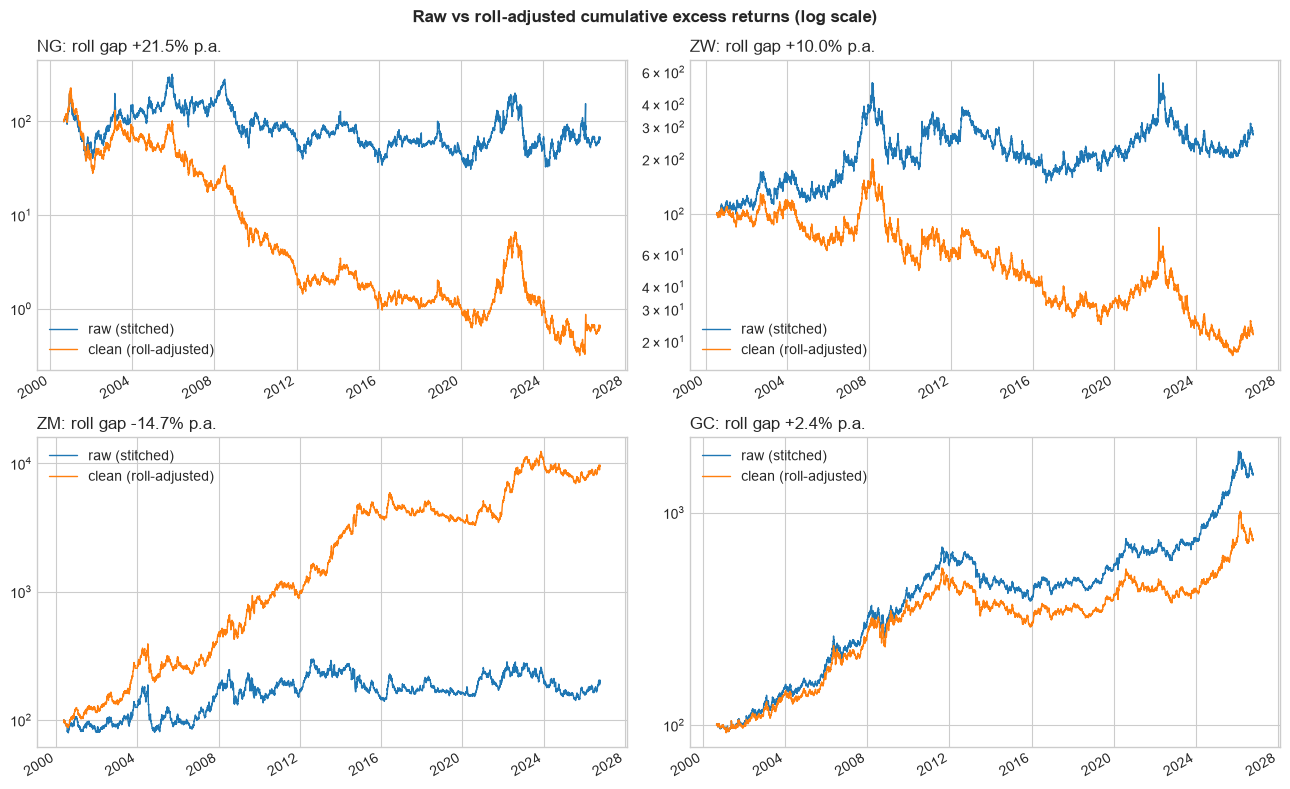

Saved: benchmarks_monthly.parquet, 02_raw_vs_clean.png


In [14]:
# ============================================================
# 02 · Cell 9 — Coverage, equal-weight benchmarks and raw vs clean chart
# ============================================================
monthly = returns.monthly
sectors = UNIVERSE.sector_map


def performance(r: pd.Series) -> pd.Series:
    """Annualised performance of a monthly excess-return series."""
    r = r.dropna()
    wealth = (1 + r).cumprod()
    ann_vol = r.std() * np.sqrt(12)
    return pd.Series(
        {
            "start": r.index[0].strftime("%Y-%m"),
            "cagr_%": ((wealth.iloc[-1]) ** (12 / len(r)) - 1) * 100,
            "vol_%": ann_vol * 100,
            "sharpe": r.mean() * 12 / ann_vol,
            "max_dd_%": (wealth / wealth.cummax() - 1).min() * 100,
        }
    )


# 1. Cross-sectional coverage
coverage = monthly.notna().sum(axis=1)
print("Contracts with a valid monthly return (average per year)")
print(coverage.groupby(coverage.index.year).mean().round(1).to_frame("n_contracts").T.to_string(), "\n")

# 2. Equal-weight benchmarks: all contracts and by sector
benchmarks = pd.DataFrame({"EW_all": monthly.mean(axis=1)})
for sector in Sector:
    members = [s for s in monthly.columns if sectors[s] == sector.value]
    benchmarks[f"EW_{sector.value}"] = monthly[members].mean(axis=1)

print("Equal-weight benchmark performance (monthly rebalanced, excess returns)")
print(benchmarks.apply(performance).T.round(2).to_string(), "\n")
benchmarks.to_parquet(PATHS.processed / "benchmarks_monthly.parquet")

# 3. Raw vs clean cumulative returns
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, symbol in zip(axes.flat, ["NG", "ZW", "ZM", "GC"]):
    pd.DataFrame(
        {"raw (stitched)": raw.index[symbol], "clean (roll-adjusted)": returns.index[symbol]}
    ).plot(ax=ax, logy=True, lw=1)
    ax.set_title(f"{symbol}: roll gap {comparison.at[symbol, 'roll_gap_pa']:+.1f}% p.a.", loc="left")
    ax.set_xlabel("")

fig.suptitle("Raw vs roll-adjusted cumulative excess returns (log scale)", fontweight="bold")
fig.tight_layout()
fig.savefig(PATHS.figures / "02_raw_vs_clean.png", dpi=150)
plt.show()
print("Saved: benchmarks_monthly.parquet, 02_raw_vs_clean.png")